In [298]:

import numpy as np
import numpy.matlib
from numpy import pi
import pandas as pd
import xarray as xr
import netCDF4 as nc
from netCDF4 import Dataset, date2num
from scipy import stats
from scipy import ndimage



import matplotlib

import argparse
import time
import shutil
from math import pi
from shapely.geometry import Point,MultiPoint
from scipy.stats import pearsonr




#Plot packages
#matplotlib.use('Agg')
import matplotlib.pyplot as plt

import cmocean
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib import colors
import cartopy.crs as ccrs
import cartopy.feature as cfeature


#system packages
import os, glob, sys, pprint, shlex,subprocess
from configparser import ConfigParser

config_object = ConfigParser()
config_object.read("config_base.ini")
config_info = config_object['CONFIG_BASE']
MODELS = config_info["MODELS"].split(',')
lon_min = int(config_info["lon_min"])
lon_max = int(config_info["lon_max"])
lat_min = int(config_info["lat_min"])
lat_max = int(config_info["lat_max"])
DATE1 = config_info["DATE_start"]
DATE2 = config_info["DATE_end"]
PROJECT = config_info["PROJECT"]
EXP_NAME = config_info["EXP_NAME"]
username = config_info["username"]
dir_work = config_info["dir_work"]
dir_in = config_info["dir_in"]
DRIFT_TIME = int(config_info['DRIFT_TIME'])
remote =  bool(config_info['remote'])
nb_repeats = int(config_info["nb_repeats"])


print("MODELS : ",MODELS)
print("Region : ",lon_min,", ",lon_max,", ",lat_min,", ",lat_max)
print("From : ",DATE1," to ",DATE2)

import datetime
import getpass
import sys
sys.path.insert(0, dir_in+"src/")
from Drift_Tools import ReturnUVlist, ExtractSurface, match_elements, StringRegion, DispDirAndLength,  SeparationDistance, TrajDistBetweenTimesteps, SepDistanceEachTimestep, LiuScore, shift360, DriftersInZoneInPeriod, coord2index

str_region = StringRegion(lon_min,lon_max,lat_min,lat_max)
dir_out=dir_work+"DRIFT/"+PROJECT+'/'+EXP_NAME+'/ZONE_'+str_region+'/'
from Drift_Tools import *
import datetime
username=getpass.getuser()
print('username: ',username)
matplotlib.use('Agg')


DD1=int(DATE1[:2])
MM1=int(DATE1[2:4])
YYYY1=int(DATE1[4:])
print(DD1,'-',MM1,'-',YYYY1)
date_start = datetime.date(YYYY1, MM1, DD1)
str_date1=date_start.strftime('%Y-%m-%d')
date_start_min1 = date_start-datetime.timedelta(days=1)

#reconstruct date_end
DD2=int(DATE2[:2])
MM2=int(DATE2[2:4])
YYYY2=int(DATE2[4:])
date_end = datetime.date(YYYY2, MM2, DD2)
str_date2=date_end.strftime('%Y-%m-%d')
date_end_plus1 = date_end+datetime.timedelta(days=1)





traj_files = []
traj_files_smag = []
traj_files_M1 = []

for MODEL in MODELS:
    traj_files_int = []
    traj_files_int += sorted(glob.glob(dir_out+'EXP/'+MODEL+'/'+'Trajectories_'+MODEL+'_*at_SVPloc.zarr'))
    traj_files.append(traj_files_int)
    traj_files_int_smag = []
    traj_files_int_smag += sorted(glob.glob(dir_out+'EXP/'+MODEL+'/'+'Trajectories_'+MODEL+'_*at_SVPloc_smag.zarr'))
    traj_files_smag.append(traj_files_int_smag)
    traj_files_int_M1 = []
    traj_files_int_M1 += sorted(glob.glob(dir_out+'EXP/'+MODEL+'/'+'Trajectories_'+MODEL+'_*at_SVPloc_M1.zarr'))
    traj_files_M1.append(traj_files_int_M1)
traj_files = np.array(traj_files)
traj_files_smag = np.array(traj_files_smag)
traj_files_M1 = np.array(traj_files_M1)





traj_lon = []
traj_lat = []
traj_time = []
for i in range(len(MODELS)):
    traj_lon_int = []
    traj_lat_int = []
    traj_time_int = []
    for file in traj_files[i]:
        ds = xr.open_dataset(file)
        traj_time_int.append(ds.time.values)
        traj_lon_int.append(ds.lon.values)
        traj_lat_int.append(ds.lat.values)
    traj_lon.append(traj_lon_int)
    traj_lat.append(traj_lat_int)
    traj_time.append(traj_time_int)

traj_lon = np.array(traj_lon)
traj_lat = np.array(traj_lat)
traj_time = np.array(traj_time)

traj_lon_smag = []
traj_lat_smag = []
traj_time_smag = []
for i in range(len(MODELS)):
    traj_lon_int = []
    traj_lat_int = []
    traj_time_int = []
    for file in traj_files_smag[i]:
        ds = xr.open_dataset(file)
        traj_time_int.append(ds.time.values)
        traj_lon_int.append(ds.lon.values)
        traj_lat_int.append(ds.lat.values)
    traj_lon_smag.append(traj_lon_int)
    traj_lat_smag.append(traj_lat_int)
    traj_time_smag.append(traj_time_int)
traj_lon_smag = np.array(traj_lon_smag)
traj_lat_smag = np.array(traj_lat_smag)
traj_time_smag = np.array(traj_time_smag)

traj_lon_M1 = []
traj_lat_M1 = []
traj_time_M1 = []
for i in range(len(MODELS)):
    traj_lon_int = []
    traj_lat_int = []
    traj_time_int = []
    for file in traj_files_M1[i]:
        ds = xr.open_dataset(file)
        traj_time_int.append(ds.time.values)
        traj_lon_int.append(ds.lon.values)
        traj_lat_int.append(ds.lat.values)
    traj_lon_M1.append(traj_lon_int)
    traj_lat_M1.append(traj_lat_int)
    traj_time_M1.append(traj_time_int)
traj_lon_M1 = np.array(traj_lon_M1)
traj_lat_M1 = np.array(traj_lat_M1)
traj_time_M1 = np.array(traj_time_M1)




#dir_in='/data/rd_exchange/pgouvenou/DATA/GlobalDriftingProgram//YEAR/'
dir_in = '/data/rd_exchange/svangennip/DATA/GlobalDriftingProgram/YEAR/'

fname_in='Drifters_'+str(YYYY1)+'.csv'
f_drifters_all=dir_in+fname_in
date_end_bis = datetime.date(YYYY2, MM2, DD2)+datetime.timedelta(days=DRIFT_TIME)
str_date3 = date_end_bis.strftime('%Y-%m-%d')
T_DRIFT = (date_end_bis -date_start).days
fout_driftersZone = 'Drifters_'+str_region+'_'+str_date1+'_'+str_date2+'.csv'
dir_drifters = dir_out+'/DRIFTERS/'


outfile2 = dir_drifters+fout_driftersZone



print('loading ',outfile2)
drifters_zone_traj = pd.read_csv(outfile2) #when unknown number of spaces separating columns
print(drifters_zone_traj.head(5))
print(drifters_zone_traj.dtypes)

    
nb_drifters_temp=len(pd.unique(drifters_zone_traj['id']))

#Sort drifter info in indiv. variables traj_lon, traj_lat, traj_id, etc...
if remote:
    nb_points = T_DRIFT*24 +24   # hourly
else :
    nb_points = (T_DRIFT+1)*4 + 1    # hourly

traj_drifter_lon   = np.reshape(drifters_zone_traj.lon.values,(nb_drifters_temp, nb_points) )
traj_drifter_lat   = np.reshape(drifters_zone_traj.lat.values,(nb_drifters_temp, nb_points) )
traj_drifter_date = np.reshape(drifters_zone_traj.date.values,(nb_drifters_temp, nb_points) )
traj_drifter_time  = np.reshape(drifters_zone_traj.time.values,(nb_drifters_temp, nb_points) )
traj_drifter_id  = np.reshape(drifters_zone_traj.id.values,(nb_drifters_temp, nb_points) )


MODELS :  ['GLO12V4', 'GLOBC', 'PSY4V3R1']
Region :  -150 ,  -111 ,  16 ,  37
From :  15012019  to  15022019
username:  pgouvenou
15 - 1 - 2019


/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'netcdf4' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'scipy' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'netcdf4' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray/backends/plugins.py:159: RuntimeWarning: 'scipy' fails while guessing
  warnings.warn(f"{engine!r} fails while guessing", RuntimeWarning)
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/xarray

loading  /data/rd_exchange/pgouvenou/DRIFT/project/test/ZONE_150W111W-16N37N//DRIFTERS/Drifters_150W111W-16N37N_2019-01-15_2019-02-15.csv
   index               id        date      time     lat      lon       t  \
0      2  300234063840660  2019-01-15  12:00:00  22.084 -143.200  23.380   
1      3  300234063840660  2019-01-15  18:00:00  22.103 -143.220  23.582   
2      4  300234063840660  2019-01-16  00:00:00  22.106 -143.220  24.586   
3      5  300234063840660  2019-01-16  06:00:00  22.102 -143.213  23.734   
4      6  300234063840660  2019-01-16  12:00:00  22.088 -143.211  23.512   

       ve     vn   speed    varlat    varlon      vart  
0 -10.128  5.741  11.642  0.000003  0.000005  0.001684  
1  -4.819  5.418   7.251  0.000003  0.000005  0.001684  
2   1.759 -0.258   1.778  0.000003  0.000005  0.001684  
3   2.180 -4.537   5.034  0.000003  0.000005  0.001684  
4  -4.301 -4.584   6.286  0.000003  0.000005  0.001682  
index       int64
id          int64
date       object
time     

In [299]:
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms

def confidence_ellipse(x, y, ax, n_std=3.0, facecolor='none', **kwargs):
    """
    Create a plot of the covariance confidence ellipse of *x* and *y*.

    Parameters
    ----------
    x, y : array-like, shape (n, )
        Input data.

    ax : matplotlib.axes.Axes
        The axes object to draw the ellipse into.

    n_std : float
        The number of standard deviations to determine the ellipse's radiuses.

    **kwargs
        Forwarded to `~matplotlib.patches.Ellipse`

    Returns
    -------
    matplotlib.patches.Ellipse
    """
    if x.size != y.size:
        raise ValueError("x and y must be the same size")

    cov = np.cov(x, y)
    pearson = cov[0, 1]/np.sqrt(cov[0, 0] * cov[1, 1])
    # Using a special case to obtain the eigenvalues of this
    # two-dimensional dataset.
    ell_radius_x = np.sqrt(1 + pearson)
    ell_radius_y = np.sqrt(1 - pearson)
    ellipse = Ellipse((0, 0), width=ell_radius_x * 2, height=ell_radius_y * 2,
                      facecolor=facecolor, **kwargs)

    # Calculating the standard deviation of x from
    # the squareroot of the variance and multiplying
    # with the given number of standard deviations.
    scale_x = np.sqrt(cov[0, 0]) * n_std
    mean_x = np.mean(x)

    # calculating the standard deviation of y ...
    scale_y = np.sqrt(cov[1, 1]) * n_std
    mean_y = np.mean(y)

    transf = transforms.Affine2D() \
        .rotate_deg(45) \
        .scale(scale_x, scale_y) \
        .translate(mean_x, mean_y)

    ellipse.set_transform(transf + ax.transData)
    return ax.add_patch(ellipse)


def confidence_ellipse_obj(x, y, n_std=3.0, facecolor='none', **kwargs):
    """
    Create a plot of the covariance confidence ellipse of *x* and *y*.

    Parameters
    ----------
    x, y : array-like, shape (n, )
        Input data.

    ax : matplotlib.axes.Axes
        The axes object to draw the ellipse into.

    n_std : float
        The number of standard deviations to determine the ellipse's radiuses.

    **kwargs
        Forwarded to `~matplotlib.patches.Ellipse`

    Returns
    -------
    matplotlib.patches.Ellipse
    """
    if x.size != y.size:
        raise ValueError("x and y must be the same size")

    cov = np.cov(x, y)
    pearson = cov[0, 1]/np.sqrt(cov[0, 0] * cov[1, 1])
    # Using a special case to obtain the eigenvalues of this
    # two-dimensional dataset.
    ell_radius_x = np.sqrt(1 + pearson)
    ell_radius_y = np.sqrt(1 - pearson)
    ellipse = Ellipse((0, 0), width=ell_radius_x * 2, height=ell_radius_y * 2,
                      facecolor=facecolor, **kwargs)

    # Calculating the standard deviation of x from
    # the squareroot of the variance and multiplying
    # with the given number of standard deviations.
    scale_x = np.sqrt(cov[0, 0]) * n_std
    mean_x = np.mean(x)

    # calculating the standard deviation of y ...
    scale_y = np.sqrt(cov[1, 1]) * n_std
    mean_y = np.mean(y)

    transf = transforms.Affine2D() \
        .rotate_deg(45) \
        .scale(scale_x, scale_y) \
        .translate(mean_x, mean_y)

    ellipse.set_transform(transf )
    return ellipse

In [300]:
matplotlib.use('Agg')
%matplotlib inline

In [302]:
dir_plot = dir_out+'PLOT/'


if not os.path.exists(dir_plot):
    print('\ncreate folder : ', dir_plot)
    # Create directory where to store results:
    os.makedirs(dir_plot)



create folder :  /data/rd_exchange/pgouvenou/DRIFT/project/test/ZONE_150W111W-16N37N/PLOT/


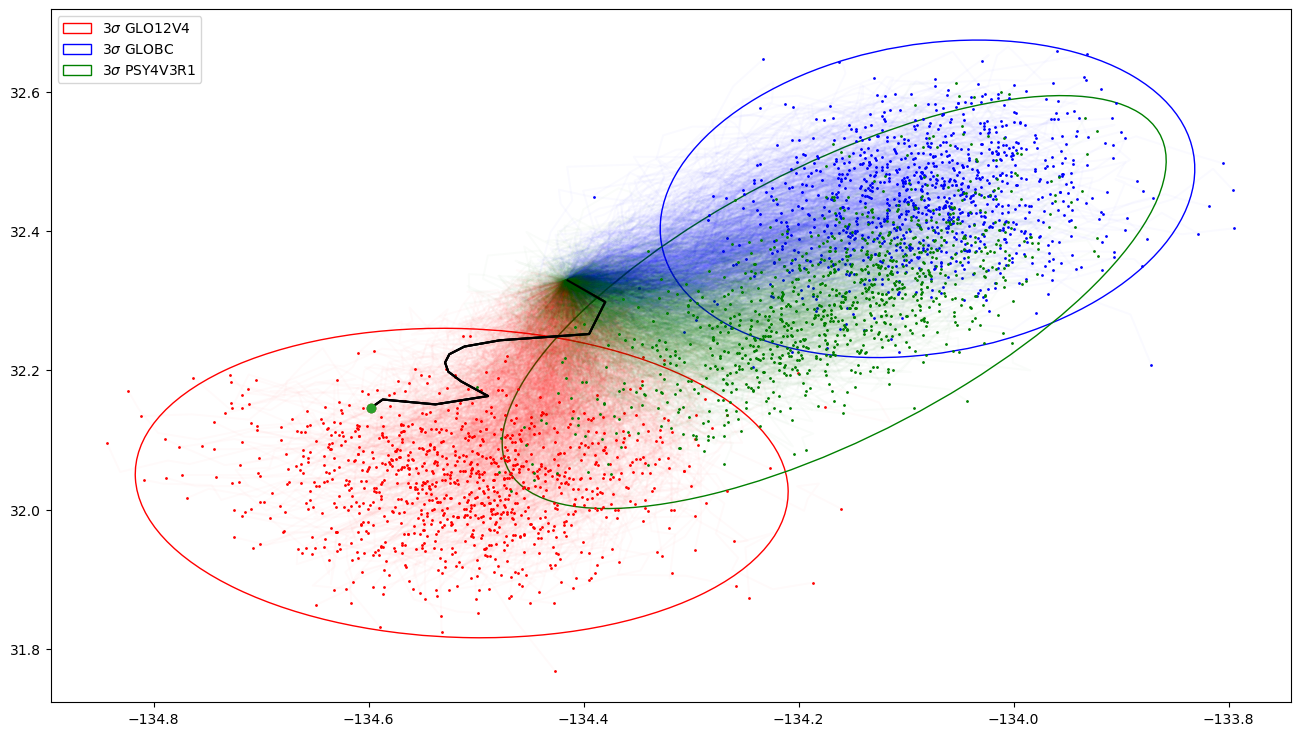

In [310]:

id = 7
day = 2
colors = ['red','blue','green']
fig,ax = plt.subplots(figsize = (16,9))

for MODELid in range (len(MODELS)):
    #fig.suptitle(MODELS[MODELid])
    ax.plot(traj_lon_M1[MODELid,day,id::nb_drifters_temp].T[-1],traj_lat_M1[MODELid,day,id::nb_drifters_temp].T[-1],'o',c = colors[MODELid],ms = 1)
    ax.plot(traj_lon_M1[MODELid,day,id::nb_drifters_temp].T,traj_lat_M1[MODELid,day,id::nb_drifters_temp].T,c=colors[MODELid],alpha = 0.02)
    confidence_ellipse(traj_lon_M1[MODELid,day,id::nb_drifters_temp].T[-1],traj_lat_M1[MODELid,day,id::nb_drifters_temp].T[-1],ax, n_std=3,label=r'$3\sigma$ '+MODELS[MODELid],edgecolor = colors[MODELid])
    if remote:
        ax.plot(traj_drifter_lon[id][0+day*24:DRIFT_TIME*24+1+day*24],traj_drifter_lat[id][0+day*24:DRIFT_TIME*24+1+day*24],c='k')
        ax.plot(traj_drifter_lon[id][0+day*24:DRIFT_TIME*24+1+day*24][-1],traj_drifter_lat[id][0+day*24:DRIFT_TIME*24+1+day*24][-1],'o')
    
    else:
        ax.plot(traj_drifter_lon[id][0+day*4:DRIFT_TIME*4+1+day*4],traj_drifter_lat[id][0+day*4:DRIFT_TIME*4+1+day*4],c='k')
        ax.plot(traj_drifter_lon[id][0+day*4:DRIFT_TIME*4+1+day*4][-1],traj_drifter_lat[id][0+day*4:DRIFT_TIME*4+1+day*4][-1],'o')
    plt.legend()


plt.savefig(dir_out+'PLOT/figure_particles.png',dpi = 400)

In [311]:
from shapely.geometry import Point, Polygon

In [312]:
in_out_array = np.zeros((traj_lon_M1.shape[0],traj_lon_M1.shape[1],int(traj_lon_M1.shape[2]/nb_repeats)))
prop_tot = []
area_ellipse = []
if remote:
    for i in range (traj_lon_M1.shape[0]):
        in_poly = 0
        tot = 0
        area_ellipse_int = []
        for day in range(traj_lon_M1.shape[1]):
            area_ellipse_int1 = []
            for dri in range(int(traj_lon_M1.shape[2]/nb_repeats)):
                ellipse = Polygon(confidence_ellipse_obj(traj_lon_M1[i,day,dri::nb_drifters_temp].T[-1],traj_lat_M1[i,day,dri::nb_drifters_temp].T[-1], n_std=3,label=r'$3\sigma$',edgecolor = 'red').get_verts())
                pt = Point((traj_drifter_lon[dri][0+day*24:DRIFT_TIME*24+1+day*24][-1],traj_drifter_lat[dri][0+day*24:DRIFT_TIME*24+1+day*24][-1]))
                if (ellipse.contains(pt)):
                    in_poly+=1
                    in_out_array[i,day,dri] = 1
                tot+=1
                area_ellipse_int1.append(ellipse.area)
            area_ellipse_int.append(area_ellipse_int1)
        print("Proportion of drifter in 99% ellipse for model '", MODELS[i],"' : ",round(in_poly/tot*100,2),"%")
        prop_tot.append(round(in_poly/tot*100,2))
        area_ellipse.append(area_ellipse_int)

else :
    for i in range (traj_lon_M1.shape[0]):
        in_poly = 0
        tot = 0
        area_ellipse_int = []
        for day in range(traj_lon_M1.shape[1]):
            area_ellipse_int1 = []
            for dri in range(int(traj_lon_M1.shape[2]/nb_repeats)):
                ellipse = Polygon(confidence_ellipse_obj(traj_lon_M1[i,day,dri::nb_drifters_temp].T[-1],traj_lat_M1[i,day,dri::nb_drifters_temp].T[-1], n_std=3,label=r'$3\sigma$',edgecolor = 'red').get_verts())
                pt = Point((traj_drifter_lon[dri][0+day*4:DRIFT_TIME*4+1+day*4][-1],traj_drifter_lat[dri][0+day*4:DRIFT_TIME*4+1+day*4][-1]))
                if (ellipse.contains(pt)):
                    in_poly+=1
                    in_out_array[i,day,dri] = 1
                tot+=1
                area_ellipse_int1.append(ellipse.area)
            area_ellipse_int.append(area_ellipse_int1)
        print("Proportion of drifter in 99% ellipse for model '", MODELS[i],"' : ",round(in_poly/tot*100,2),"%")
        prop_tot.append(round(in_poly/tot*100,2))
        area_ellipse.append(area_ellipse_int)

Proportion of drifter in 99% ellipse for model ' GLO12V4 ' :  57.23 %
Proportion of drifter in 99% ellipse for model ' GLOBC ' :  41.6 %
Proportion of drifter in 99% ellipse for model ' PSY4V3R1 ' :  56.93 %


/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


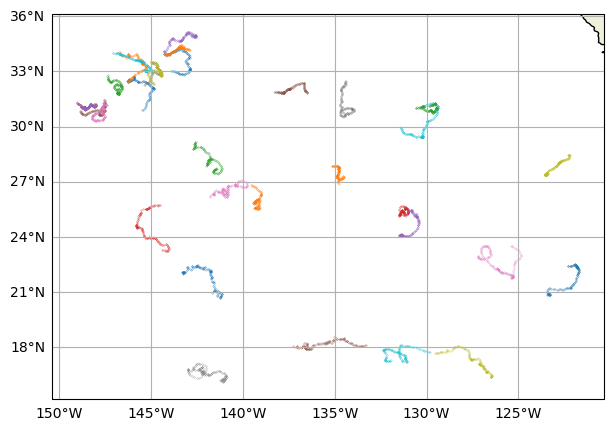

In [313]:
fig = plt.figure(figsize = (9,5))
axs=plt.axes(projection=ccrs.PlateCarree())
axs.coastlines()
axs.add_feature(cfeature.LAND)
gl = axs.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.xlabels_top = False
gl.ylabels_right = False
axs.plot(traj_drifter_lon.T,traj_drifter_lat.T,'o',ms = 0.2)
#plt.savefig(dir_out+'PLOT/drifters_trajectories_good_interp.png',dpi = 400)

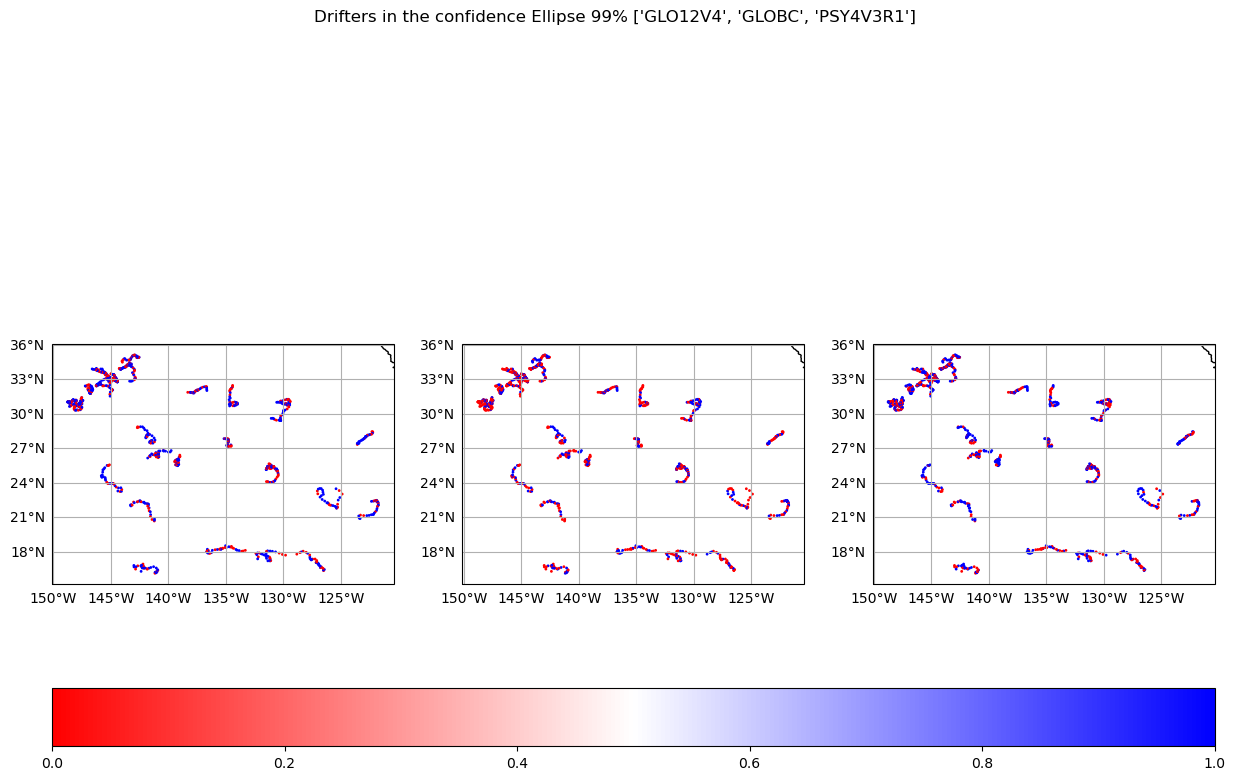

In [315]:
fig,axs = plt.subplots(figsize = (5*len(MODELS),9),ncols=len(MODELS),subplot_kw={'projection': ccrs.PlateCarree()})
if len(MODELS) == 1:
    for i in range(len(MODELS)):
        axs.coastlines()
        axs.add_feature(cfeature.LAND)
        gl = axs.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        gl.xlabels_top = False
        gl.ylabels_right = False
        fig.suptitle('Drifters in the confidence Ellipse 99% ' + str(MODELS) ,fontsize = 12)
        if remote:
            
            im = axs.scatter(traj_drifter_lon[:,::24][:,:-3][:,:in_out_array.shape[1]],
                             traj_drifter_lat[:,::24][:,:-3][:,:in_out_array.shape[1]],
                             c = in_out_array[i],cmap = 'bwr_r',s = 1)
        else :
            
            im = axs.scatter(traj_drifter_lon[:,::4][:,:-3][:,:in_out_array.shape[1]],
                             traj_drifter_lat[:,::4][:,:-3][:,:in_out_array.shape[1]],
                             c = in_out_array[i],cmap = 'bwr_r',s = 1)
    
    fig.colorbar(im, ax=axs,orientation = 'horizontal')    
else : 
    for i in range(len(MODELS)):
        axs[i].coastlines()
        gl = axs[i].gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        gl.xlabels_top = False
        gl.ylabels_right = False
        fig.suptitle('Drifters in the confidence Ellipse 99% ' + str(MODELS) ,fontsize = 12)
        if remote:
            
            im = axs[i].scatter(traj_drifter_lon[:,::24][:,:-3][:,:in_out_array.shape[1]],
                             traj_drifter_lat[:,::24][:,:-3][:,:in_out_array.shape[1]],
                             c = in_out_array[i],cmap = 'bwr_r',s = 1)
        else :
            
            im = axs[i].scatter(traj_drifter_lon[:,::4][:,:-3][:,:in_out_array.shape[1]],
                             traj_drifter_lat[:,::4][:,:-3][:,:in_out_array.shape[1]],
                             c = in_out_array[i],cmap = 'bwr_r',s = 1)
    
    fig.colorbar(im, ax=axs.ravel().tolist(),orientation = 'horizontal')
plt.savefig(dir_out+'PLOT/confidence_ellipse.png',dpi = 400)

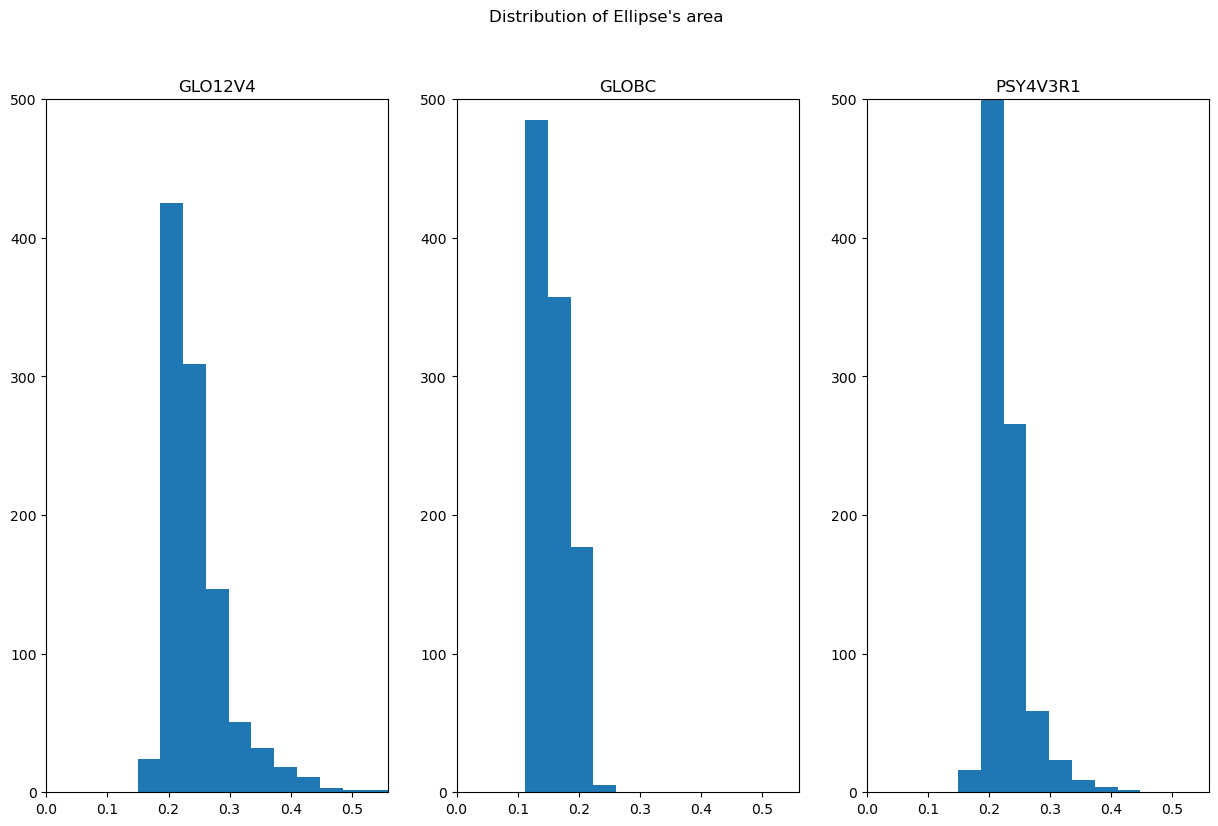

In [317]:
fig,axs = plt.subplots(figsize = (5*len(MODELS),9),ncols=len(MODELS))
if len(MODELS) == 1:
    for i in range(len(MODELS)):
        fig.suptitle("Distribution of Ellipse's area ",fontsize = 12)
        axs.set_title(MODELS[i])
        axs.hist( np.array(area_ellipse[i]).flatten(),bins = 15,range=(0,np.max(np.array(area_ellipse).flatten())))
        axs.set_xlim([0,np.max(np.array(area_ellipse).flatten())])
        axs.set_ylim([0,500])    
else : 
    for i in range(len(MODELS)):
        fig.suptitle("Distribution of Ellipse's area ",fontsize = 12)
        axs[i].set_title(MODELS[i])
        axs[i].hist( np.array(area_ellipse[i]).flatten(),bins = 15,range=(0,np.max(np.array(area_ellipse).flatten())))
        axs[i].set_xlim([0,np.max(np.array(area_ellipse).flatten())])
        axs[i].set_ylim([0,500])


plt.savefig(dir_out+'PLOT/area_ellipse.png',dpi = 400)

In [318]:
cell_size = 1
grid = np.meshgrid(np.linspace(lon_min,lon_max,int((lon_max - lon_min )/cell_size)+ 1),np.linspace(lat_min,lat_max,int((lat_max - lat_min )/cell_size)+ 1))

In [319]:
sum_traj = np.zeros(grid[0].shape)

if len(MODELS)==2:
    sum_elli = np.array([np.zeros(grid[0].shape),np.zeros(grid[0].shape)])
    
elif len(MODELS)==3:
    sum_elli = np.array([np.zeros(grid[0].shape),np.zeros(grid[0].shape),np.zeros(grid[0].shape)])

elif len(MODELS) == 1:
    sum_elli = np.array([np.zeros(grid[0].shape)])
for mod in range (in_out_array.shape[0]):
    for i in range (grid[0].shape[0]-1):
        for j in range (grid[0].shape[1]-1):
            
            #print(grid[0][i,j],grid[0][i,j]+cell_size)
            #print(grid[1][i,j],grid[1][i,j]+cell_size)
            if remote:
                indice = np.where(np.array((grid[0][i,j]< traj_drifter_lon[:,::24][:,:-3][:,:in_out_array.shape[1]])*(traj_drifter_lon[:,::24][:,:-3][:,:in_out_array.shape[1]]<grid[0][i,j]+cell_size)*
                 (grid[1][i,j]< traj_drifter_lat[:,::24][:,:-3][:,:in_out_array.shape[1]])*(traj_drifter_lat[:,::24][:,:-3][:,:in_out_array.shape[1]]<grid[1][i,j]+cell_size)))
            else :
                indice = np.where(np.array((grid[0][i,j]< traj_drifter_lon[:,::4][:,:-3][:,:in_out_array.shape[1]])*(traj_drifter_lon[:,::4][:,:-3][:,:in_out_array.shape[1]]<grid[0][i,j]+cell_size)*
                 (grid[1][i,j]< traj_drifter_lat[:,::4][:,:-3][:,:in_out_array.shape[1]])*(traj_drifter_lat[:,::4][:,:-3][:,:in_out_array.shape[1]]<grid[1][i,j]+cell_size)))
            if indice[0].shape[0]!= 0:
                sum_traj[i,j] = indice[0].shape[0]
                sum_elli[mod,i,j] = np.sum(in_out_array[mod][indice[1],indice[0]])
                

In [320]:
sum_traj_tot = np.zeros(grid[0].shape)

for i in range (grid[0].shape[0]-1):
    for j in range (grid[0].shape[1]-1):
        
        #print(grid[0][i,j],grid[0][i,j]+cell_size)
        #print(grid[1][i,j],grid[1][i,j]+cell_size)
        if remote:
            indice = np.where(np.array((grid[0][i,j]< traj_drifter_lon[:,::24][:,:-3])*(traj_drifter_lon[:,::24][:,:-3]<grid[0][i,j]+cell_size)*
                 (grid[1][i,j]< traj_drifter_lat[:,::24][:,:-3])*(traj_drifter_lat[:,::24][:,:-3]<grid[1][i,j]+cell_size)))
        else:    
            indice = np.where(np.array((grid[0][i,j]< traj_drifter_lon[:,::4][:,:-3])*(traj_drifter_lon[:,::4][:,:-3]<grid[0][i,j]+cell_size)*
                 (grid[1][i,j]< traj_drifter_lat[:,::4][:,:-3])*(traj_drifter_lat[:,::4][:,:-3]<grid[1][i,j]+cell_size)))
        if indice[0].shape[0]!= 0:
            sum_traj_tot[i,j] = indice[0].shape[0]
            

In [321]:
sum_traj_tot[np.where(sum_traj_tot==0)] = np.nan

/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '


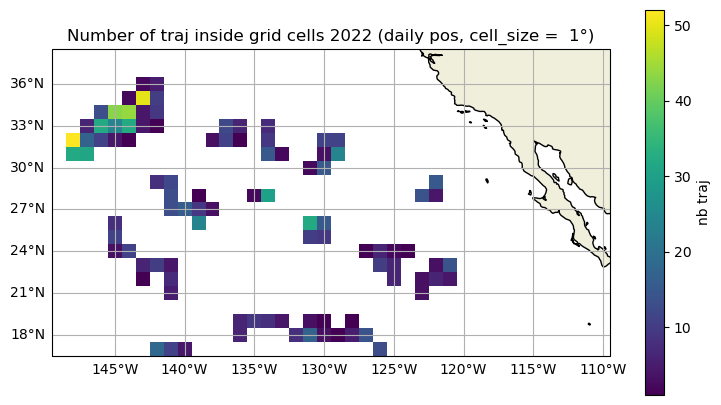

In [322]:
fig = plt.figure(figsize = (9,5))
axs=plt.axes(projection=ccrs.PlateCarree())
plt.title('Number of traj inside grid cells 2022 (daily pos, cell_size =  '+str(cell_size)+'°)')
cb = axs.pcolormesh(grid[0]+cell_size,grid[1]+cell_size,sum_traj_tot)
gl = axs.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
gl.xlabels_top = False
gl.ylabels_right = False
axs.coastlines()
axs.add_feature(cfeature.LAND)
plt.colorbar(cb,label =  'nb traj')
plt.savefig(dir_out+'PLOT/number_of_traj_in_grid_cells.png',dpi = 400)

/tmp/ipykernel_15625/3291257979.py:25: RuntimeWarning: invalid value encountered in divide
  cb = axs[i].pcolormesh(grid[0]+cell_size,grid[1]+cell_size,sum_elli[i]/sum_traj * 100,vmin = 0,vmax = 100)
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/home/pgouvenou/miniconda3/envs/env_validation_tools/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:487: UserWarning: The .ylabels_right attribute is deprecated. Please use .right_labels to toggle visibility instead.
  warnings.warn('The .ylabels_right attribute is deprecated. Please '
/tmp/ipykernel_15625/3291257979.py:25: RuntimeWarning: invalid value encountered in divide
  cb = axs[i].pcolormesh(grid[0]+cell_size,grid[1]+cell_size,sum_elli[i]/sum_traj * 100,vmin = 0,vmax = 100)
/home/pgouvenou/mi

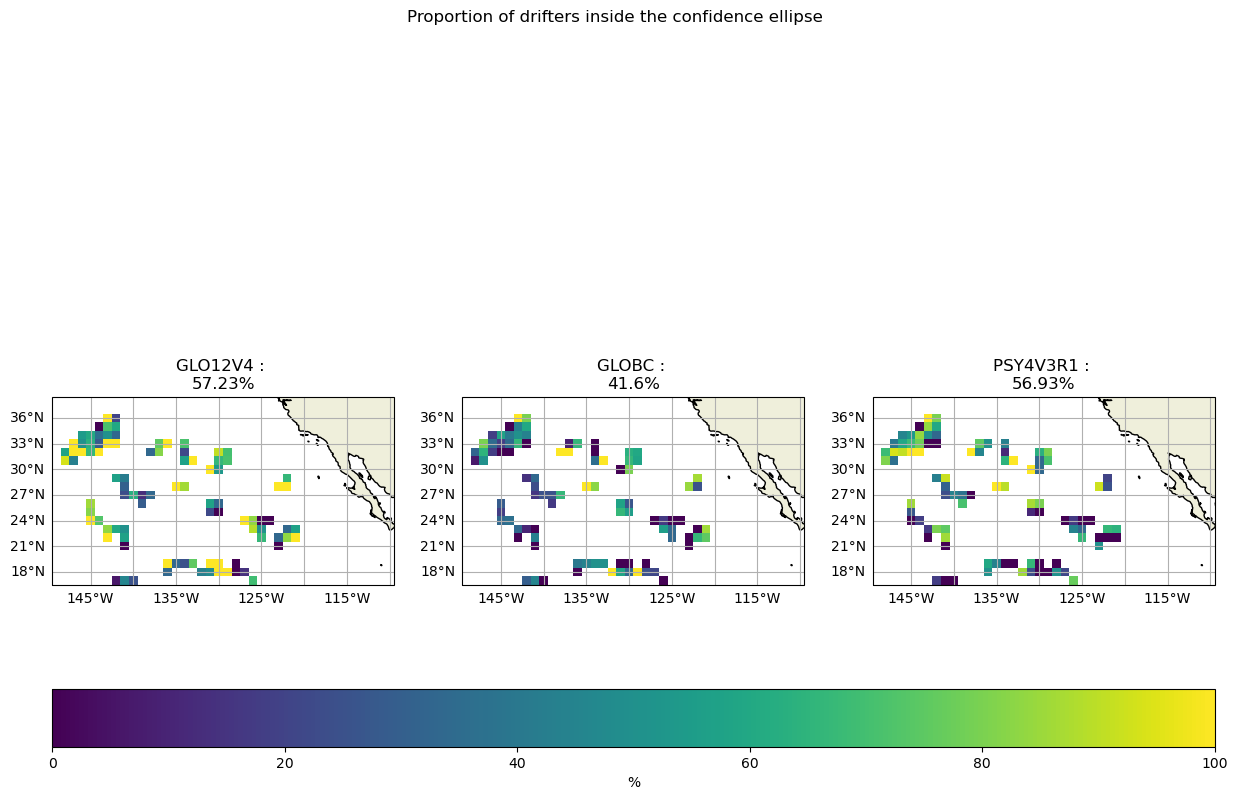

In [323]:
fig,axs = plt.subplots(figsize = (5*len(MODELS),9),ncols=len(MODELS),subplot_kw={'projection': ccrs.PlateCarree()})
if len(MODELS) == 1:
    for i in range(len(MODELS)):
        axs.coastlines()
        axs.add_feature(cfeature.LAND)
        gl = axs.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        gl.xlabels_top = False
        gl.ylabels_right = False
        fig.suptitle('Proportion of drifters inside the confidence ellipse',fontsize = 12)
        axs.set_title(MODELS[i]+' : \n'+str(prop_tot[i])+"%")
        cb = axs.pcolormesh(grid[0]+cell_size,grid[1]+cell_size,sum_elli[i]/sum_traj * 100,vmin = 0,vmax = 100)
        axs.add_feature(cfeature.LAND)
    fig.colorbar(cb, ax=axs,orientation = 'horizontal',label="%")

    
else :   
    for i in range(len(MODELS)):
        axs[i].coastlines()
        axs[i].add_feature(cfeature.LAND)
        gl = axs[i].gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
        gl.xlabels_top = False
        gl.ylabels_right = False
        fig.suptitle('Proportion of drifters inside the confidence ellipse',fontsize = 12)
        axs[i].set_title(MODELS[i]+' : \n'+str(prop_tot[i])+"%")
        cb = axs[i].pcolormesh(grid[0]+cell_size,grid[1]+cell_size,sum_elli[i]/sum_traj * 100,vmin = 0,vmax = 100)
        axs[i].add_feature(cfeature.LAND)

    fig.colorbar(cb, ax=axs.ravel().tolist(),orientation = 'horizontal',label="%")
plt.savefig(dir_out+'PLOT/map_proportion_ellipse.png',dpi = 400)